In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

# Setup
def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "config.py").exists():
            return p
    raise FileNotFoundError("Could not find project root")

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from config import PROCESSED_DATA_DIR, IMAGES_DIR

sns.set_style("whitegrid")
df = pd.read_csv(PROCESSED_DATA_DIR / "clean_online_retail.csv", parse_dates=['invoice_date'])

# Define snapshot date (1 day after last purchase)
snapshot_date = df['invoice_date'].max() + pd.Timedelta(days=1)
print(f"Data loaded. Snapshot date: {snapshot_date.date()}")

Data loaded. Snapshot date: 2011-12-10


In [2]:
# Group by customer
rfm = df.groupby('customer_id').agg({
    'invoice_date': lambda x: (snapshot_date - x.max()).days, # Recency
    'invoice': 'nunique',                                     # Frequency
    'total_spend': 'sum'                                      # Monetary
}).reset_index()

rfm.columns = ['customer_id', 'recency', 'frequency', 'monetary']

# Create the target variable (Churn: 1 if recency > 90, else 0)
rfm['churned'] = (rfm['recency'] > 90).astype(int)

print(f"RFM Matrix created for {len(rfm)} customers.")
print(f"Churn Rate: {rfm['churned'].mean():.1%}")
rfm.head()

RFM Matrix created for 4338 customers.
Churn Rate: 33.4%


,customer_id,recency,frequency,monetary,churned
0,12346,326,1,77183.60,1
1,12347,2,7,4310.00,0
2,12348,75,4,1797.24,0
3,12349,19,1,1757.55,0
4,12350,310,1,334.40,1


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

# Features (X) and Target (y)
X = rfm[['frequency', 'monetary']]  # We exclude 'recency' because churn is defined by it!
y = rfm['churned']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")

Train size: 3470 | Test size: 868


In [4]:
# Model 1: Logistic Regression (Baseline)
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', random_state=42))
])
lr_model.fit(X_train, y_train)
lr_probs = lr_model.predict_proba(X_test)[:, 1]
lr_auc = roc_auc_score(y_test, lr_probs)

# Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)
rf_probs = rf_model.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, rf_probs)

print(f"Logistic Regression ROC-AUC: {lr_auc:.3f}")
print(f"Random Forest ROC-AUC:       {rf_auc:.3f}")

Logistic Regression ROC-AUC: 0.785
Random Forest ROC-AUC:       0.785


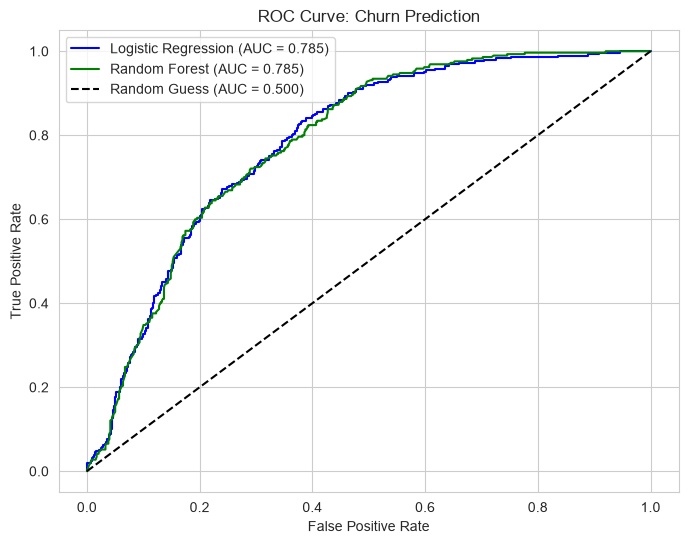


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.61      0.72       578
           1       0.51      0.81      0.63       290

    accuracy                           0.68       868
   macro avg       0.69      0.71      0.67       868
weighted avg       0.75      0.68      0.69       868



In [5]:
# Plot ROC Curve
plt.figure(figsize=(8, 6))
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {lr_auc:.3f})', color='blue')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_auc:.3f})', color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Churn Prediction')
plt.legend()
plt.savefig(IMAGES_DIR / "churn_roc_curve.png", dpi=150)
plt.show()

# Print classification report for Random Forest
print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_model.predict(X_test)))